In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from scipy.stats import pearsonr
import mar

In [2]:
iyr=1980
fyr=2024
domain='GRf'; domainM='GRp'
var='PRE';units='mm/month'

In [3]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/'
plotsDir='/home/santolam/RECAP/figures/'


In [4]:
model1='MAR'
res1=str('5kmx5km')
nx=ny=10

ds_RF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout/{domainM}/spin2/work/monthly/'+
                            'RF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['RF']
ds_RF = ds_RF_raw.rename({'TIME': 'time'})
units_RF=ds_RF.units
###
ds_SF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout/{domainM}/spin2/work/monthly/'+
                            'SF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['SF']
ds_SF = ds_SF_raw.rename({'TIME': 'time'})
units_SF=ds_SF.units

ds_TF=ds_RF+ds_SF



ds1=ds_TF[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))


In [5]:
ds_grid= xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')
LONS=ds_grid.LON[ny:-ny,nx:-nx].values
LATS=ds_grid.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grid.SH[ny:-ny,nx:-nx]
dsICE=ds_grid.ICE[ny:-ny,nx:-nx]

In [6]:
field1_SH= dsSH.assign_coords({
    'lat': (('y', 'x'), LATS),
    'lon': (('y', 'x'),LONS)
})

In [7]:
field1=ds1.assign_coords({
    'lat': (('Y', 'X'), LATS),
    'lon': (('Y', 'X'),LONS)
})
#field1=field1.rename({"Y":"y","X":"x"})

In [8]:
print(field1_SH.shape,field1.shape)

(62, 96) (540, 62, 96)


In [9]:
###Select the real domain
latS=field1.lat.min(); latN=field1.lat.max()
lonW=field1.lon.min(); lonE=field1.lon.max()


In [10]:
model3='aphro'
res3=str('0.25°x0.25°')

fileName3='APHRO_mon_MA_025deg_V1101_EXR1.1951-2015.nc'
ds3 = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/aphro/monthly/'
                      +fileName3,decode_times=False)['precip']
start_date = pd.Timestamp('1951-01-01')
# Create new time index
nmonths = ds3.time.size
time_new = pd.date_range(start=start_date, periods=nmonths, freq='MS')  # 'MS' = Month Start
# Replace time in dataset
ds3['time'] = time_new
ds3=dom.reversing_lat(ds3)
ds3=ds3.rename({'latitude':'lat','longitude':'lon'})
field3_mm_day=ds3.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_mm_day=field3_mm_day.sel(time=slice(str(iyr),str(fyr)))

# Convert mm/day to mm/month
days_in_month = field3_mm_day['time'].dt.days_in_month
field3= field3_mm_day * days_in_month

field3.shape


(432, 16, 31)

In [11]:
ds3_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_aphro.nc')['elevation']
ds3_SH=ds3_SH_raw.rename({'latitude':'lat','longitude':'lon'})
ds3_SH=dom.reversing_lat(ds3_SH)
field3_SH=ds3_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_SH.shape

(16, 31)

In [12]:
###model 4
model4='gpcp'
res4=str('1.0°x1.0°')

fileName4='precip_mon.gpcp_v2020_1891_2019_10.nc'
ds4= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'
                     +model4+'/'+fileName4)['precip']
print(ds4.attrs) 
#ds4=dom.reversing_lat(ds4)
#units in mm/month -> mm/day

field4=ds4.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

#month_length = field40.time.dt.days_in_month
#
#field4=field40/month_length
field4=field4.sel(time=slice(str(iyr),str(2019)))
field4.shape


{'long_name': 'gpcc full data monthly product version 2020, precipitation per grid', 'units': 'mm/month', 'code': 20, 'institution': 'DWD'}


(480, 4, 8)

In [13]:
ds4_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_gpcp.nc')['elevation']
#ds4_SH=ds4_SH.rename({'latitude':'lat','longitude':'lon'})

field4_SH=ds4_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [14]:
print(field4.shape,field4_SH.shape)

(480, 4, 8) (4, 8)


In [15]:
#print(field4.lat[0:2],field3.lat[0:2])

In [16]:
model5='cru'
res5=str('0.5°x0.5°')

fileName5='cru_ts4.05.1901.2020.pre.dat.nc'
ds5_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+model5+'/'+fileName5)['pre']
ds5=dom.reversing_lat(ds5_raw)
field5=ds5.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field5=field5.sel(time=slice(str(iyr),str(2020)))

In [17]:
#field5

In [18]:
ds5_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_cru_hma_grid.nc')['elevation']
ds5_SH=dom.reversing_lat(ds5_SH_raw)
field5_SH=ds5_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

In [19]:
model6='chirps'
res6='0.05°x0.05°'
fileName6='chirps-v2.0.monthly.nc'
ds6 = xr.open_dataset(sourceData+model6+'/'+fileName6)['precip']
ds6=ds6.rename({'latitude':'lat','longitude':'lon'})
ds6=dom.reversing_lat(ds6)
field6=ds6.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


print(field6.shape)

(531, 78, 158)


In [20]:
ds6_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_chirps_hma_grid.nc')['elevation']
ds6_SH=ds6_SH.rename({'latitude':'lat','longitude':'lon'})
ds6_SH=dom.reversing_lat(ds6_SH)
field6_SH=ds6_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field6_SH.shape

(78, 158)

In [21]:
#field5_SH[:,:].plot()

In [22]:
model7='HARv2'
res7='10kmx10km'
#variable='prcp'
fileName7='HARv2_mon_d10km_d_2d_prcp_1980-2023.nc'
ds7_raw0= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7)['prcp']
ds7_raw=ds7_raw0*24 #mm/h
# Calculate days in each month
days_in_month7= ds7_raw['time'].dt.days_in_month
# Convert to mm/month
ds7= ds7_raw* days_in_month7

def xy_sel_dom(ds,latS,latN,lonW,lonE):
    #latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain(domain)
    lat_str = ''
    lon_str = ''
    other_dims_str = []
    for dim in ds.coords:
        print(dim)
        if dim in ['lat', 'latitude','LON']:
            lat_str = dim
        elif dim in ['lon', 'longitude','LAT']:
            lon_str = dim
        else:
            other_dims_str.append(dim)
    mask = (
        (latS < ds[lat_str]) & ( ds[lat_str] < latN) 
    & (lonW < ds[lon_str]) & ( ds[lon_str] < lonE)
    )
    field_dom=ds.where(mask,drop=True)
    return field_dom

# Apply mask (non-NaN where the condition is True)
#hgt_subset = hgt.where(mask, drop=True)
field7=xy_sel_dom(ds7.sel(time=slice(str(iyr),str(2023))),latS,latN,lonW,lonE)

time
lon
lat
west_east
south_north


In [23]:
#field7[0,:,:].plot()

In [24]:
fileName7_grF='HARv2_d10km_static_hgt.nc'
ds7_grM= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7_grF)
ds7SH=ds7_grM['hgt'][0,:,:]
#dsSH
field7_SH=xy_sel_dom(ds7SH,latS,latN,lonW,lonE)


time
west_east
south_north
lon
lat


In [25]:

## SAME ANALYSIS BUT FOR multiple data sets(at the same time): lists

dsList=[field1,
        field3,field4,field5,field6,
        field7]
modelList=[model1,
           model3,model4,model5,model6,
           model7]
resList=[res1,
         res3,res4,res5,res6,
         res7]
nameList=list(zip(modelList,resList))

In [26]:
nameList

[('MAR', '5kmx5km'),
 ('aphro', '0.25°x0.25°'),
 ('gpcp', '1.0°x1.0°'),
 ('cru', '0.5°x0.5°'),
 ('chirps', '0.05°x0.05°'),
 ('HARv2', '10kmx10km')]

In [27]:
elevList=[field1_SH,field3_SH,field4_SH,field5_SH,field6_SH,field7_SH]
print(len(elevList))

6


In [28]:
level_bounds = [(0, 2500), (2500, 4500), (4500, 5500), (5500, 7500)]


In [29]:
maskList_field1 = []
for lev_min, lev_max in level_bounds:
    mask = (field1_SH >= lev_min) & (field1_SH < lev_max)
    maskList_field1.append(mask)

maskList_field3 = []
for lev_min, lev_max in level_bounds:
    mask = (field3_SH >= lev_min) & (field3_SH < lev_max)
    maskList_field3.append(mask)

maskList_field4 = []
for lev_min, lev_max in level_bounds:
    mask = (field4_SH >= lev_min) & (field4_SH < lev_max)
    maskList_field4.append(mask)

maskList_field5 = []
for lev_min, lev_max in level_bounds:
    mask = (field5_SH >= lev_min) & (field5_SH < lev_max)
    maskList_field5.append(mask)

maskList_field6 = []
for lev_min, lev_max in level_bounds:
    mask = (field6_SH >= lev_min) & (field6_SH < lev_max)
    maskList_field6.append(mask)

maskList_field7 = []
for lev_min, lev_max in level_bounds:
    mask = (field7_SH >= lev_min) & (field7_SH < lev_max)
    maskList_field7.append(mask)

In [30]:
def compute_seasonal_means(field, season_months):
    """Compute seasonal means (per year) using a month selection loop."""
    month = field['time'].dt.month
    year = field['time'].dt.year
    year = xr.where(month == 12, year + 1, year)  # shift Dec → next year

    results = []
    for season, months in season_months.items():
        # Select the months for this season
        vals = field.sel(time=field['time'].dt.month.isin(months))
        vals = vals.assign_coords(year=year.sel(time=vals.time))
        # Mean over months per year
        vals_mean = vals.groupby('year').mean('time', skipna=True)
        vals_mean = vals_mean.expand_dims({'season': [season]})
        results.append(vals_mean)

    return xr.concat(results, dim='season')


In [31]:
seasonList= ['DJF', 'MAM', 'JJA', 'SON']
season_months = {
    'DJF': [12, 1, 2],
    'MAM': [3, 4, 5],
    'JJA': [6, 7, 8],
    'SON': [9, 10, 11]
}


In [ ]:
#seasonList = ['DJFM', 'AM', 'JJAS', 'ON']
#season_months = {
 #   'DJFM': [12, 1, 2, 3],
 #   'AM': [4, 5],
 #   'JJAS': [6, 7, 8, 9],
 #   'ON': [10, 11]
#}

In [49]:
field1_season_all = compute_seasonal_means(field1, season_months)
field3_season_all = compute_seasonal_means(field3, season_months)
field4_season_all = compute_seasonal_means(field4, season_months)
field5_season_all = compute_seasonal_means(field5, season_months)
field6_season_all = compute_seasonal_means(field6, season_months)
field7_season_all = compute_seasonal_means(field7, season_months)


In [163]:
season=seasonList[3]
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

def compute_mean_for_masks(field_season, mask_list, dims):
    mean_vals = []
    for mask in mask_list:
        masked = field_season.where(mask.values)
        for dim in dims:
            masked = masked.mean(dim)
        mean_vals.append(masked)
    return mean_vals

# Then apply it like this:
ac_mean_vals_field1 = compute_mean_for_masks(field1_season, maskList_field1,  ['X', 'Y'])
ac_mean_vals_field3 = compute_mean_for_masks(field3_season, maskList_field3, ['lon', 'lat'])
ac_mean_vals_field4= compute_mean_for_masks(field4_season, maskList_field4,  ['lon', 'lat'])
ac_mean_vals_field5= compute_mean_for_masks(field5_season, maskList_field5,  ['lon', 'lat'])
ac_mean_vals_field6= compute_mean_for_masks(field6_season, maskList_field6,  ['lon', 'lat'])
ac_mean_vals_field7 = compute_mean_for_masks(field7_season, maskList_field7,  ['south_north', 'west_east'])

In [164]:
nameList

[('MAR', '5kmx5km'),
 ('aphro', '0.25°x0.25°'),
 ('gpcp', '1.0°x1.0°'),
 ('cru', '0.5°x0.5°'),
 ('chirps', '0.05°x0.05°'),
 ('HARv2', '10kmx10km')]

In [165]:
colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

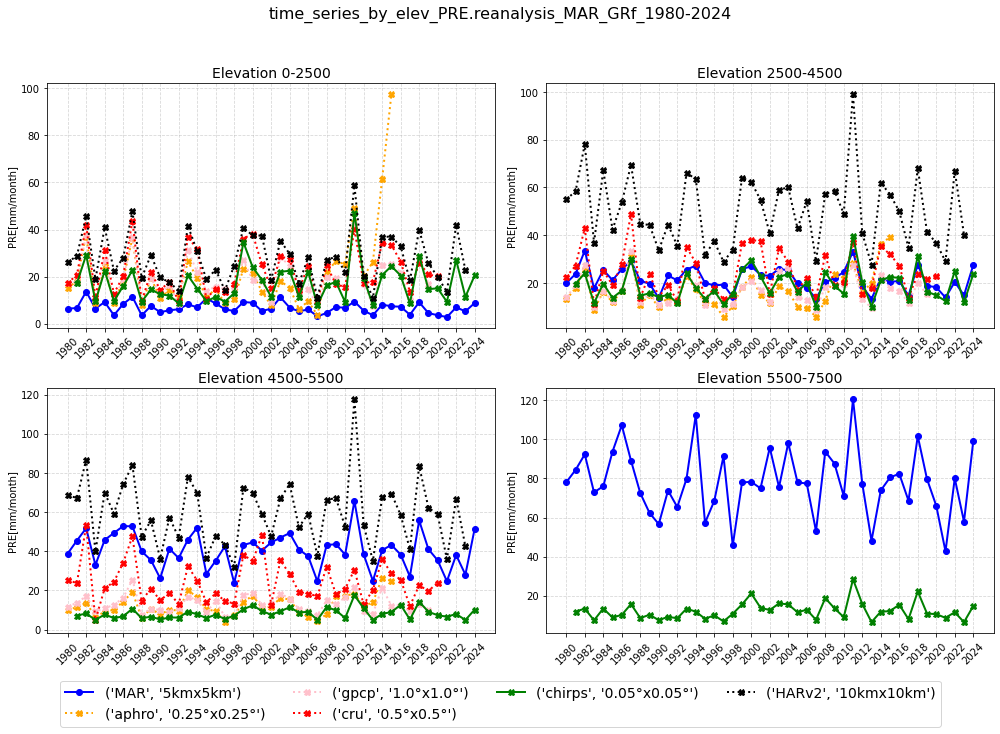

In [166]:
plotname=f'time_series_by_elev_{var}.reanalysis_MAR_{domain}_{str(iyr)}-{str(fyr)}'

colors = colorList
elev_labels = ['0-2500', '2500-4500', '4500-5500', '5500-7500']

months = ac_mean_vals_field1[0].year#np.arange(1, 13)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=False, sharey=False)
axs = axs.flatten()

for i in range(4):  # 4 elevation bands
    ax = axs[i]

    # Plot one line per dataset
    ax.plot(ac_mean_vals_field1[0].year, ac_mean_vals_field1[i].values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
    ax.plot(ac_mean_vals_field3[0].year, ac_mean_vals_field3[i].values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
    ax.plot(ac_mean_vals_field4[0].year, ac_mean_vals_field4[i].values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
    ax.plot(ac_mean_vals_field5[0].year,ac_mean_vals_field5[i].values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
    ax.plot(ac_mean_vals_field6[0].year ,ac_mean_vals_field6[i].values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
    ax.plot(ac_mean_vals_field7[0].year, ac_mean_vals_field7[i].values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

    ax.set_title(f'Elevation {elev_labels[i]}', fontsize=14)
    ax.set_xticks(months)
    ax.set_ylabel(f'{var}[{units}]')
    years=ac_mean_vals_field1[0].year.values
    xticks = years[::2]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks, rotation=45)
    ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
#plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')


plt.show()

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/time_series_by_elev_PRE.reanalysis_MAR_GRf_1980-2024.png


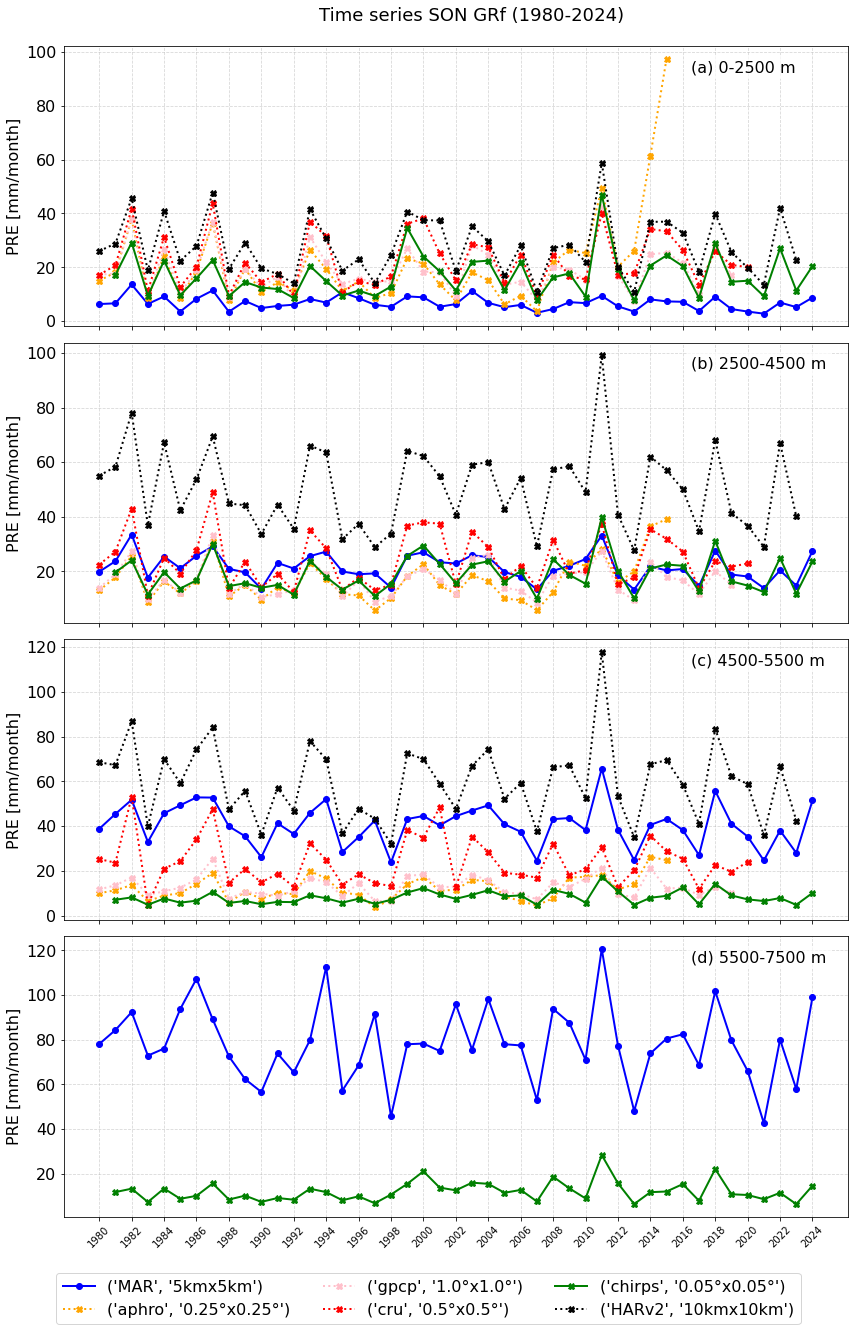

In [167]:
labels_fig=['(a)','(b)','(c)','(d)']
colors = colorList
elev_labels = ['0-2500', '2500-4500', '4500-5500', '5500-7500']
months = np.arange(1, 13)

# --- Crear figura con 4 filas y 1 columna ---
fig, axs = plt.subplots(4, 1, figsize=(12, 20), sharex=True, sharey=False)
axs = axs.flatten()

for i, ax in enumerate(axs):
    ax.plot(ac_mean_vals_field1[0].year, ac_mean_vals_field1[i].values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
    ax.plot(ac_mean_vals_field3[0].year, ac_mean_vals_field3[i].values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
    ax.plot(ac_mean_vals_field4[0].year, ac_mean_vals_field4[i].values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
    ax.plot(ac_mean_vals_field5[0].year,ac_mean_vals_field5[i].values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
    ax.plot(ac_mean_vals_field6[0].year ,ac_mean_vals_field6[i].values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
    ax.plot(ac_mean_vals_field7[0].year, ac_mean_vals_field7[i].values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

    #ax.set_title(f'Elevation {elev_labels[i]}', fontsize=14)
    ax.set_ylabel(f'{var} [{units}]',fontsize=16)
    #ax.axhline(y=0, color='grey', linestyle='-', linewidth=1)
    years=ac_mean_vals_field1[0].year.values
    xticks = years[::2]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks, rotation=45)
    
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.text(
    0.8, 0.95,                      # x, y in axes fraction (0–1)
    f'{labels_fig[i]} {elev_labels[i]} m',   # text string
    transform=ax.transAxes,          # interpret coords relative to axes
    fontsize=16,
    #fontweight='bold',
    va='top', ha='left',
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # optional box
)
    #ax.set_aspect(1)
# Título general
fig.suptitle(plotname, fontsize=16)

# Leyenda común abajo
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.03),
    ncol=3,
    fontsize=16,
    frameon=True
)

# Ajustar espacio para la leyenda
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.suptitle(f'Time series {season} {domain} ({iyr}-{fyr})',fontsize=18,y=0.95,x=0.55)
plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"

plotname=f'time_series_by_elev_{var}.reanalysis_MAR_{domain}_{str(iyr)}-{str(fyr)}'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [168]:
import numpy as np
from scipy.stats import pearsonr

def compute_stats(sim_vals, ref_vals):
    """
    Compute RMSE, bias, and correlation (R) between reference and simulation.
    Only uses the common years between both.
    """
    # Encontrar los años comunes
    ref_years =ref_vals.year.values 
    sim_years=sim_vals.year.values
    common_years = np.intersect1d(ref_years, sim_years)
    if len(common_years) == 0:
        raise ValueError("No overlapping years between reference and simulation!")

    # Seleccionar los valores correspondientes
    ref = np.array([ref_vals[np.where(ref_years == y)[0][0]] for y in common_years])
    sim = np.array([sim_vals[np.where(sim_years == y)[0][0]] for y in common_years])

    # Filtrar valores finitos
    mask = np.isfinite(ref) & np.isfinite(sim)
    ref = ref[mask]
    sim = sim[mask]

    if len(ref) < 2:
        return np.nan, np.nan, np.nan  # no hay datos suficientes

    # Calcular estadísticas
    bias = np.mean(sim - ref)
    rmse = np.sqrt(np.mean((sim - ref) ** 2))
    r, _ = pearsonr(ref, sim)

    return bias, rmse, r#, len(common_years)


In [169]:
i=0
ref = ac_mean_vals_field1[i]#.values  # referencia
mod3 = ac_mean_vals_field3[i]#.values
mod4 = ac_mean_vals_field4[i]#.values
mod5 = ac_mean_vals_field5[i]#.values
mod6 = ac_mean_vals_field6[i]#.values
mod7 = ac_mean_vals_field7[i]#.values

In [170]:
ref

<xarray.DataArray (year: 46)>
array([ 6.3894453,  6.6692224, 13.65403  ,  6.437995 ,  9.198736 ,
        3.6198559,  8.352469 , 11.447327 ,  3.5543854,  7.530135 ,
        4.9080844,  5.688249 ,  6.1603036,  8.261017 ,  6.935562 ,
       10.772432 ,  8.588161 ,  6.1214767,  5.382641 ,  9.235931 ,
        8.893533 ,  5.396346 ,  6.3820243, 11.237359 ,  6.838908 ,
        5.229577 ,  6.0776687,  3.1586375,  4.544836 ,  7.0986514,
        6.7349153,  9.428076 ,  5.5395484,  3.6013505,  8.125887 ,
        7.3809795,  7.2301087,  3.8183043,  9.114734 ,  4.527304 ,
        3.6068947,  2.8314595,  6.953977 ,  5.2619314,  8.785707 ,
              nan], dtype=float32)
Coordinates:
  * year     (year) int64 1980 1981 1982 1983 1984 ... 2021 2022 2023 2024 2025
    season   <U3 'SON'

In [171]:

results = {}

for name, model in zip(
    nameList[1:],
    [mod3, mod4, mod5, mod6, mod7]
):
    bias, rmse, r = compute_stats(ref, model)
    results[name] = {'BIAS': bias, 'RMSE': rmse, 'R': r}

df_stats = pd.DataFrame(results).T
print(df_stats)

                         BIAS       RMSE         R
aphro  0.25°x0.25° -14.328338  22.049303  0.371476
gpcp   1.0°x1.0°   -12.150767  13.879412  0.763940
cru    0.5°x0.5°   -15.591481  17.645386  0.656759
chirps 0.05°x0.05° -10.341110  12.392455  0.608473
HARv2  10kmx10km   -21.014884  22.954432  0.704473


In [172]:
biasList,rmseList, rList=[],[],[]
for i in range(0,4):
    bias, rmse, r = compute_stats(ac_mean_vals_field1[i], ac_mean_vals_field6[i])
    print(bias,rmse, r)
    biasList.append(bias);rmseList.append(rmse); rList.append(r)

-10.34111 12.392455 0.6084730875281459
2.696778 4.9809113 0.7486698937175039
32.37733 33.29112 0.6640803862186644
66.04888 67.675766 0.6096994981247823


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/time_series_by_elev_PRE.reanalysis_MAR_GRf_SON_1980-2024_eval.png


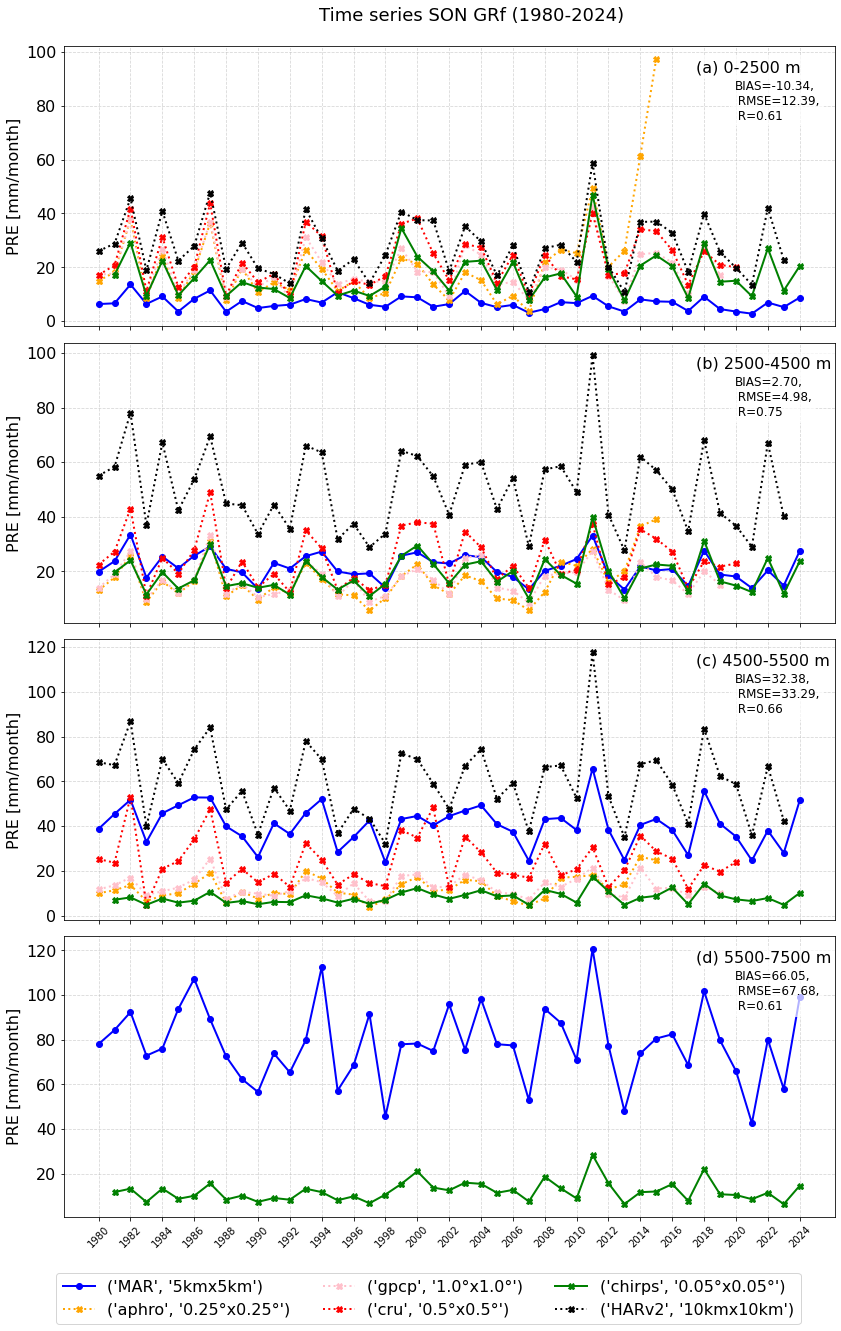

In [173]:
labels_fig=['(a)','(b)','(c)','(d)']
colors = colorList
elev_labels = ['0-2500', '2500-4500', '4500-5500', '5500-7500']
months = np.arange(1, 13)

# --- Crear figura con 4 filas y 1 columna ---
fig, axs = plt.subplots(4, 1, figsize=(12, 20), sharex=True, sharey=False)
axs = axs.flatten()

for i, ax in enumerate(axs):
    ax.plot(ac_mean_vals_field1[0].year, ac_mean_vals_field1[i].values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
    ax.plot(ac_mean_vals_field3[0].year, ac_mean_vals_field3[i].values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
    ax.plot(ac_mean_vals_field4[0].year, ac_mean_vals_field4[i].values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
    ax.plot(ac_mean_vals_field5[0].year,ac_mean_vals_field5[i].values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
    ax.plot(ac_mean_vals_field6[0].year ,ac_mean_vals_field6[i].values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
    ax.plot(ac_mean_vals_field7[0].year, ac_mean_vals_field7[i].values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

    #ax.set_title(f'Elevation {elev_labels[i]}', fontsize=14)
    ax.set_ylabel(f'{var} [{units}]',fontsize=16)
    #ax.axhline(y=0, color='grey', linestyle='-', linewidth=1)
    years=ac_mean_vals_field1[0].year.values
    xticks = years[::2]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks, rotation=45)
    
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid(True, linestyle='--', alpha=0.5)
   
    ax.text(
    0.82, 0.95,                      # x, y in axes fraction (0–1)
    f'{labels_fig[i]} {elev_labels[i]} m',   # text string
    transform=ax.transAxes,          # interpret coords relative to axes
    fontsize=16,
    #fontweight='bold',
    va='top', ha='left',
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # optional box
)
    #ax.set_aspect(1)
    metrics_text = f"BIAS={biasList[i]:.2f},\n RMSE={rmseList[i]:.2f},\n R={rList[i]:.2f}"
    
    ax.text(
        0.87, 0.88,                                  # x, y en fracción de axes
        f'{metrics_text}',  # texto concatenado
        transform=ax.transAxes,
        fontsize=12,
        va='top', ha='left',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
    )
fig.suptitle(plotname, fontsize=16)

# Leyenda común abajo
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.03),
    ncol=3,
    fontsize=16,
    frameon=True
)

# Ajustar espacio para la leyenda
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.suptitle(f'Time series {season} {domain} ({iyr}-{fyr})',fontsize=18,y=0.95,x=0.55)
plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"

plotname=f'time_series_by_elev_{var}.reanalysis_MAR_{domain}_{season}_{str(iyr)}-{str(fyr)}_eval'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()
